# `roselab_facemap`: a tour of the face-camera data

Facemap (Syeda et al. 2024, *Nat Neurosci* 27:187) turns a face video into a few signals per camera frame:

* **motion energy**: how much the face moved from one frame to the next, as one number;
* **motion SVD** (`motSVD`): temporal components of the frame-to-frame *changes*, with spatial masks;
* **movie SVD** (`movSVD`): temporal components of the *frames themselves*.

The spatial masks are a **basis**. Temporal components are comparable only between videos decomposed in the **same
run**, because only those share a basis. Leon Kremers therefore concatenated the registered face videos of one imaging
site and stimulus type, ran facemap once, and split the result back per scan (32 *site runs*). Earlier he had run facemap
on each video alone (231 *per-video runs*).

`roselab_facemap` stores both generations side by side, each run as its own row. It also stores the DAQ time of every
facemap row, by four methods. This notebook shows what is stored, how to query it, and how the stored values were
checked. Design: `docs/FACEMAP_SCHEMA_PROPOSAL.md`.

**Contents**
1. Connect (read-only)
2. The tables
3. Inventory: runs, segments, animals
4. Addressing runs: one scan in two generations
5. One site run: segments and Leon's split
6. The spatial basis: average frame, masks, singular values
7. Traces: motion energy and components
8. The clock: four ways to time a facemap row
9. An independent clock check: face motion vs running
10. Comparing sessions within one run
11. Validation against Leon's numbers
12. The 4-frame shift in 15 segments
13. Special cases and caveats
14. Query cheat-sheet

## 1. Connect (read-only)

In [1]:
import os, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN marker frames (low DLC likelihood) are expected
warnings.filterwarnings("ignore", message="pkg_resources is deprecated")
import matplotlib.pyplot as plt
import logging
import datajoint as dj
logging.getLogger("datajoint").setLevel(logging.WARNING)   # no connection log (host address) in the notebook

dj.config.load(os.path.expanduser(os.environ.get("DJ_CONF", "~/adamacs/dj_local_conf.json")))
dj.config["database.use_tls"] = False        # LAN only: this env's OpenSSL fails the server's TLS handshake
dj.conn().query("SET SESSION transaction_read_only = 1")
assert dj.conn().query("SELECT @@transaction_read_only").fetchone()[0] == 1

vm = lambda name: dj.create_virtual_module(name, name, create_schema=False, create_tables=False)
fm, ev, md_, se, ld, be = (vm(s) for s in ("roselab_facemap", "roselab_event", "roselab_model", "roselab_session",
                                            "roselab_leondrift", "roselab_behavior"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
print("connected; read-only guard on")

connected; read-only guard on


## 2. The tables

```
FacemapParamSet (Lookup)        how a run was made: 'leon_per_video_2026' | 'leon_site_concat_2026'
SyncMethod (Lookup)             camera_frames | gate_rule | start_anchored | aux_cam_first_n
FacemapTask (Manual)            one run: an ORDERED manifest of face videos (.Video)
FacemapProcessing (Imported)    the run file (sha256, size), frame totals
  .Segment                      per video: frame offset in the run, frame counts, video_frame_offset, Leon's split-file check
FacialSignal (Imported)         the signals
  .Summary .Region              average frame / motion; region 0 = full frame
  .Basis                        per SVD: all singular values, first 100 spatial masks
  .Trace                        per segment: motion energy, first 100 motSVD / movSVD components (facemap rows)
  .Position                     per segment: median position in the run's basis, from ALL components
FrameSync (Computed)            DAQ time of every facemap row, per method
SegmentDistance (Computed)      distances between the segments of one run (Leon's svd_distances)
```

Every array is in the external store. Traces are in **facemap rows**; `FrameSync` turns rows into DAQ times.

In [2]:
fm.FacemapParamSet.proj("video_assembly", "paramset_desc").fetch(format="frame")

,video_assembly,paramset_desc
facemap_paramset,,
leon_per_video_2026,per_video,"Leon Kremers, Feb-Apr 2026: facemap on each fa..."
leon_site_concat_2026,site_concat_registered,"Leon Kremers, May-Nov 2026: registered face vi..."


In [3]:
fm.SyncMethod.fetch(format="frame")

,sync_description
sync_method,
aux_cam_first_n,Leon Kremers' original extraction.facemotion_a...
camera_frames,event.Event '<camera>_frames' (e.g. bench2p_fa...
gate_rule,the last n aux_cam triggers strictly inside ma...
start_anchored,frame i = aux_cam trigger 121 + i after main_t...


## 3. Inventory: runs, segments, animals

In [4]:
seg = pd.DataFrame((fm.FacemapProcessing.Segment * fm.FacemapTask.Video * fm.FacemapTask * fm.FacemapParamSet).fetch(
    "facemap_task_id", "segment_index", "session_id", "scan_id", "video_assembly", "task_label", "n_frames",
    "n_frames_video", "frames_match", "video_frame_offset", "split_motion", "split_matches_run", as_dict=True))
subj = pd.DataFrame((se.Session & seg[["session_id"]].drop_duplicates().to_dict("records")).fetch("session_id", "subject", as_dict=True))
seg = seg.merge(subj, on="session_id")
print("runs:", seg.facemap_task_id.nunique(), "| segments:", len(seg), "| scans:", seg.scan_id.nunique(),
      "| animals:", seg.subject.nunique(), "| hours of face video:", round(seg.n_frames.sum() / 60 / 3600, 1))
seg.groupby(["video_assembly"]).agg(runs=("facemap_task_id", "nunique"), segments=("scan_id", "size"),
                                    frames=("n_frames", "sum")).assign(hours=lambda d: (d.frames / 216000).round(1))

runs: 263 | segments: 525 | scans: 338 | animals: 16 | hours of face video: 509.0


,runs,segments,frames,hours
video_assembly,,,,
per_video,231,231,49826990,230.7
site_concat_registered,32,294,60107616,278.3


In [5]:
pd.crosstab(seg.subject, seg.video_assembly)

video_assembly,per_video,site_concat_registered
subject,,
ROS-1841,22,22
ROS-1846,23,22
ROS-1881,22,22
ROS-1907,22,22
ROS-1912,22,22
ROS-1985,23,14
ROS-1987,7,14
ROS-2077,15,8
ROS-2083,15,8


A scan can be in both generations: a per-video run and a site run. Those are separate rows with different bases;
they are never merged.

## 4. Addressing runs: one scan in two generations

In [6]:
SCAN = "scan9FOWAIBH"
runs = (fm.FacemapTask * fm.FacemapParamSet) & (fm.FacemapTask.Video & {"scan_id": SCAN})
runs.proj("video_assembly", "task_label", "same_site_id", "run_identity").fetch(format="frame")

,,run_identity,same_site_id,task_label,video_assembly
facemap_task_id,facemap_paramset,,,,
32999c1e0a57,leon_per_video_2026,file:/datajoint-data/data/leonk/LE_ROS-1841_20...,,,per_video
3d5d1e1b01c4,leon_site_concat_2026,file:/datajoint-data/data/leonk/analysis/facem...,sess9FOTVMAL,images,site_concat_registered


In [7]:
SITE_TASK = (runs & {"video_assembly": "site_concat_registered"}).fetch1("facemap_task_id")
PV_TASK = (runs & {"video_assembly": "per_video"}).fetch1("facemap_task_id")
print("site run", SITE_TASK, "| per-video run", PV_TASK)

site run 3d5d1e1b01c4 | per-video run 32999c1e0a57


## 5. One site run: segments and Leon's split

In [8]:
s = seg[seg.facemap_task_id == SITE_TASK].sort_values("segment_index")
print((fm.FacemapProcessing & {"facemap_task_id": SITE_TASK}).fetch1("run_file", "n_frames_total", "run_file_bytes"))
s[["segment_index", "scan_id", "n_frames", "n_frames_video", "frames_match", "video_frame_offset", "split_motion", "split_matches_run"]]

('/datajoint-data/data/leonk/analysis/facemap_registered_videos/sess9FOTVMAL_images/unified_registered_video_proc.npy', np.int64(3238465), np.int64(20583879103))


,segment_index,scan_id,n_frames,n_frames_video,frames_match,video_frame_offset,split_motion,split_matches_run
293,0,scan9FOWAIBH,294390,294390,1,0,split,1.0
294,1,scan9FOXK90S,294378,294378,1,0,split,1.0
295,2,scan9FOYO7M7,294355,294355,1,0,split,1.0
296,3,scan9FOZV4RF,294363,294363,1,0,split,1.0
297,4,scan9FP12UVN,294446,294446,1,0,split,1.0
298,5,scan9FP28QH0,294434,294434,1,0,split,1.0
299,6,scan9FP3GJAU,294383,294383,1,0,split,1.0
300,7,scan9FP4MQR4,294408,294408,1,0,split,1.0
301,8,scan9FP5TKME,294412,294412,1,0,split,1.0
302,9,scan9FP70H97,294458,294458,1,0,split,1.0


* `n_frames` are facemap rows, `n_frames_video` the video's frames; equal here.
* `split_matches_run`: Leon's per-scan copy (`<scan>_face_cam_concatenate_proc.npy`) equals the run's slice (all 294
  split files do). `split_motion = full_concat` marks the May-2026 copies that kept the whole concatenated motion trace.

## 6. The spatial basis: average frame, masks, singular values

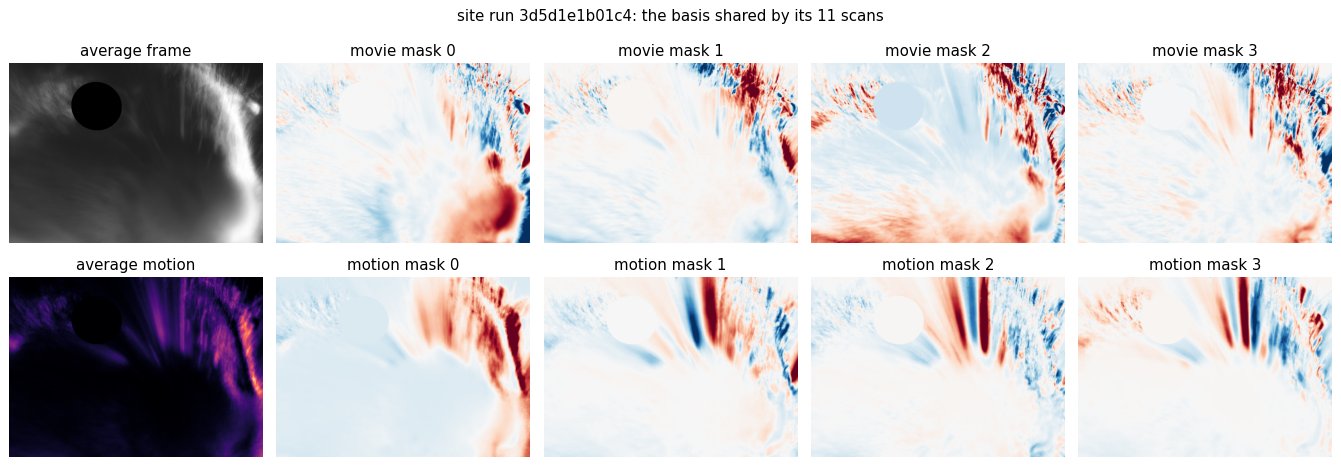

In [9]:
k_site = {"facemap_task_id": SITE_TASK, "roi_no": 0}
avg_f, avg_m = (fm.FacialSignal.Summary & {"facemap_task_id": SITE_TASK}).fetch1("avg_frame", "avg_motion")
mot_m, mot_sv = (fm.FacialSignal.Basis & k_site & {"svd": "motion"}).fetch1("masks", "singular_values")
mov_m, mov_sv = (fm.FacialSignal.Basis & k_site & {"svd": "movie"}).fetch1("masks", "singular_values")
fig, ax = plt.subplots(2, 5, figsize=(15, 5.5))
ax[0, 0].imshow(avg_f, cmap="gray"); ax[0, 0].set_title("average frame")
ax[1, 0].imshow(avg_m, cmap="magma"); ax[1, 0].set_title("average motion")
for i in range(4):
    for row, M, name in ((0, mov_m, "movie"), (1, mot_m, "motion")):
        v = np.percentile(np.abs(M[..., i]), 99)
        ax[row, i + 1].imshow(M[..., i], cmap="RdBu_r", vmin=-v, vmax=v); ax[row, i + 1].set_title(f"{name} mask {i}")
for a in ax.ravel(): a.axis("off")
plt.suptitle(f"site run {SITE_TASK}: the basis shared by its {len(s)} scans"); plt.tight_layout()

The eye is dark in the average frame: Leon blacked out an ellipse around it before facemap, so pupil and eye-position
changes do not enter the face components (they are in `pupil_tracking`). Motion masks pick out the snout, whisker pad
and jaw.

variance in the first 100 components: motion 76.2 %, movie 88.4 %


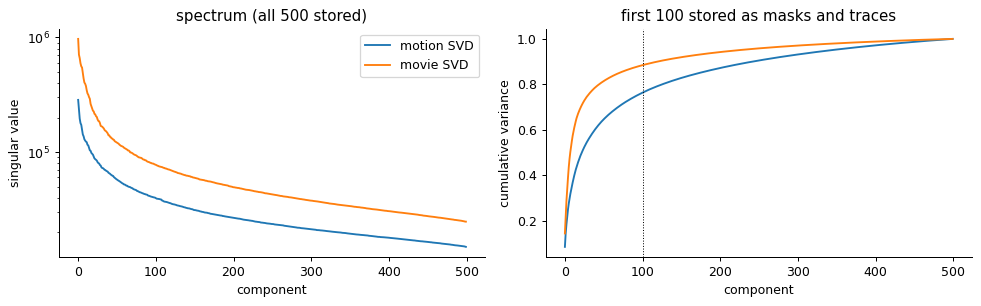

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for sv, name in ((mot_sv, "motion SVD"), (mov_sv, "movie SVD")):
    ax[0].semilogy(sv, label=name); ax[1].plot(np.cumsum(sv ** 2) / np.sum(sv ** 2), label=name)
ax[0].set(xlabel="component", ylabel="singular value", title="spectrum (all 500 stored)")
ax[1].axvline(100, color="k", lw=0.8, ls=":"); ax[1].set(xlabel="component", ylabel="cumulative variance", title="first 100 stored as masks and traces")
ax[0].legend(); plt.tight_layout()
print("variance in the first 100 components: motion %.1f %%, movie %.1f %%" % (
    100 * np.sum(mot_sv[:100] ** 2) / np.sum(mot_sv ** 2), 100 * np.sum(mov_sv[:100] ** 2) / np.sum(mov_sv ** 2)))

## 7. Traces: motion energy and components

rows 294390 | mot_svd (294390, 100) float32 | first time 4.774 s, last 4921.070 s


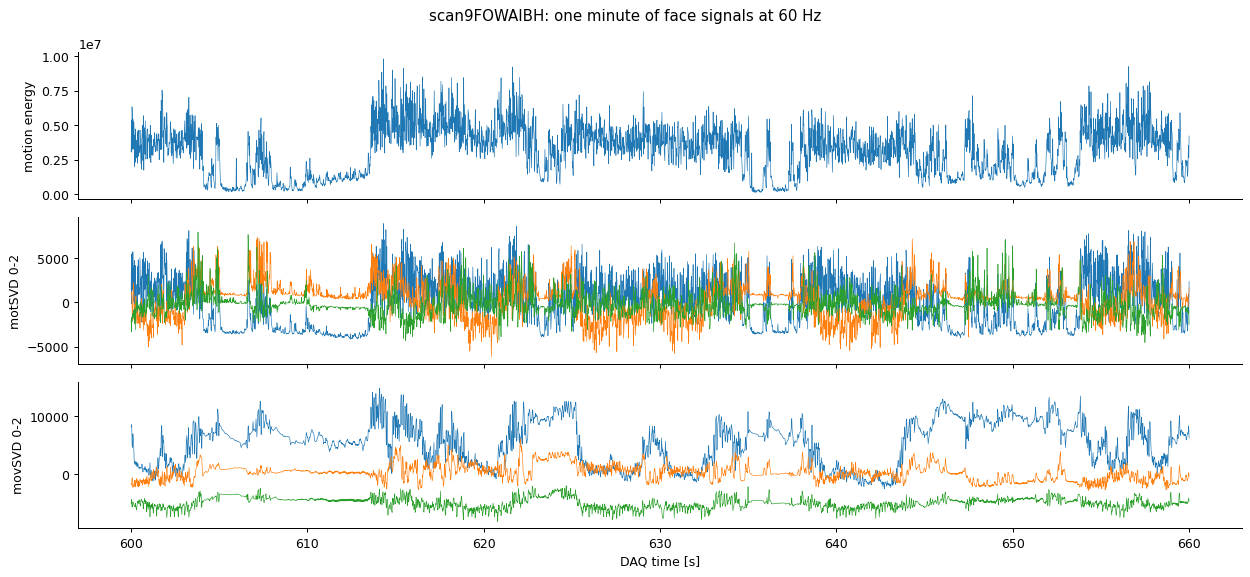

In [11]:
k_seg = {"facemap_task_id": SITE_TASK, "roi_no": 0, "segment_index": int(s[s.scan_id == SCAN].segment_index.iloc[0])}
energy, mot, mov = (fm.FacialSignal.Trace & k_seg).fetch1("motion_energy", "mot_svd", "mov_svd")
t_cam = (fm.FrameSync & k_seg & {"sync_method": "camera_frames"}).fetch1("frame_times")
print("rows", energy.size, "| mot_svd", mot.shape, mot.dtype, "| first time %.3f s, last %.3f s" % (t_cam[0], t_cam[-1]))
w = (t_cam > 600) & (t_cam < 660)
fig, ax = plt.subplots(3, 1, figsize=(14, 6.5), sharex=True)
ax[0].plot(t_cam[w], energy[w], lw=0.5); ax[0].set_ylabel("motion energy")
ax[1].plot(t_cam[w], mot[w, :3], lw=0.5); ax[1].set_ylabel("motSVD 0-2")
ax[2].plot(t_cam[w], mov[w, :3], lw=0.5); ax[2].set_ylabel("movSVD 0-2"); ax[2].set_xlabel("DAQ time [s]")
plt.suptitle(f"{SCAN}: one minute of face signals at 60 Hz"); plt.tight_layout()

## 8. The clock: four ways to time a facemap row

The camera is triggered (`aux_cam`, 60 Hz) from before the recording gate opens until after it closes, but Bonsai saves
frames only from about 2 s (≈ 121 triggers) after the gate opens until the gate closes. So:

| method | frame i gets | use |
|---|---|---|
| `camera_frames` | stored event `bench2p_face_frames` i | recordings that passed the v1-drift-audit timing QC |
| `gate_rule` | the last n `aux_cam` pulses inside the gate | others with ~121 unsaved pulses |
| `start_anchored` | pulse 121 + i after the gate opens | the 4 recordings with another unsaved count |
| `aux_cam_first_n` | the first n `aux_cam` pulses | Leon's original code, 2.9–6.0 s early; reproduction only |

A facemap row r is video frame r + `video_frame_offset` (section 12).

In [12]:
fs = pd.DataFrame((fm.FrameSync * fm.FacemapTask.Video).fetch(
    "scan_id", "facemap_task_id", "segment_index", "sync_method", "count_status", "n_unsaved", "n_frames_untimed", "first_frame_s", as_dict=True))
pd.crosstab(fs.sync_method, fs.count_status)

count_status,events_longer,events_shorter,exact,no_events
sync_method,,,,
aux_cam_first_n,525,0,0,0
camera_frames,0,0,440,85
gate_rule,525,0,0,0
start_anchored,514,11,0,0


In [13]:
one = fs[(fs.facemap_task_id == SITE_TASK) & (fs.scan_id == SCAN)].set_index("sync_method")
T = {m: (fm.FrameSync & k_seg & {"sync_method": m}).fetch1("frame_times") for m in one.index}
print(one[["count_status", "n_unsaved", "n_frames_untimed", "first_frame_s"]])
print("\ncamera_frames == gate_rule:", np.array_equal(T["camera_frames"], T["gate_rule"]))
print("aux_cam_first_n is early by %.3f s" % np.nanmedian(T["gate_rule"] - T["aux_cam_first_n"]))
print("start_anchored - gate_rule: %.3f s (unsaved = %d, not exactly 121)" % (
    np.nanmedian(T["start_anchored"] - T["gate_rule"]), one.loc["gate_rule", "n_unsaved"]))

                  count_status  n_unsaved  n_frames_untimed  first_frame_s
sync_method                                                               
aux_cam_first_n  events_longer        NaN                 0        0.99995
camera_frames            exact        NaN                 0        4.77415
gate_rule        events_longer      123.0                 0        4.77415
start_anchored   events_longer      123.0                 0        4.74075

camera_frames == gate_rule: True
aux_cam_first_n is early by 3.774 s
start_anchored - gate_rule: -0.033 s (unsaved = 123, not exactly 121)


     scan_id  n_unsaved
scan9FPZHKKB       78.0
scan9FQ1UYJD       87.0
scan9FQACAG8      140.0
scan9FSGVYRY       99.0
scan9FU4FXMQ       82.0
scan9FU5O5W5       96.0
scan9FUEM78C       94.0
scan9FVIY9TQ       83.0
scan9FVK3VDN      129.0
scan9FVLBRHY      155.0
scan9FVVG5LV      165.0
scan9FVZ0LB0      137.0
scan9FW07FNQ    27726.0
scan9FXTKOX2     9146.0
scan9FXTNTHG     9355.0
scan9G2HLHF1      129.0


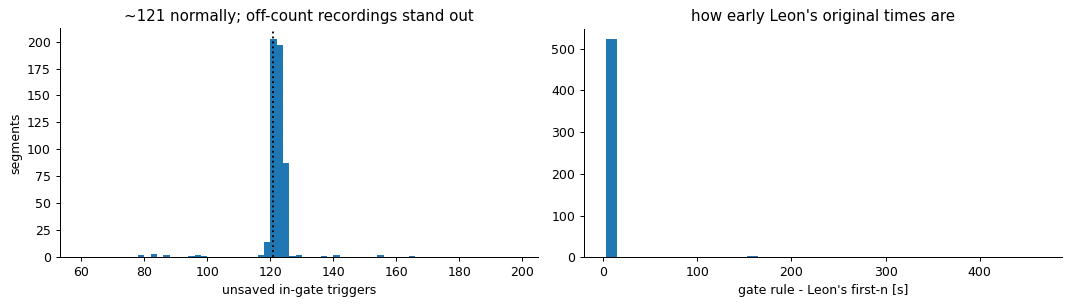

In [14]:
gr = fs[fs.sync_method == "gate_rule"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(gr.n_unsaved, bins=np.arange(60, 200, 2)); ax[0].axvline(121, color="k", ls=":")
ax[0].set(xlabel="unsaved in-gate triggers", ylabel="segments", title="~121 normally; off-count recordings stand out")
lead = (fs[fs.sync_method == "gate_rule"].set_index(["facemap_task_id", "segment_index"]).first_frame_s
        - fs[fs.sync_method == "aux_cam_first_n"].set_index(["facemap_task_id", "segment_index"]).first_frame_s)
ax[1].hist(lead.dropna(), bins=40); ax[1].set(xlabel="gate rule - Leon's first-n [s]", title="how early Leon's original times are")
plt.tight_layout()
print(gr[(gr.n_unsaved < 116) | (gr.n_unsaved > 126)][["scan_id", "n_unsaved"]].drop_duplicates().to_string(index=False))

### 8b. Which method for which recording

16 recordings have no stored camera events **and** an unusual count of unsaved triggers (outside 121 ± 5). For them
the gate rule assumes the video ends at the gate end, which it does not; the start-anchored rule fits instead. The
test below is independent of the face camera: paw speed from the **body** camera's DLC markers against the treadmill
belt speed (both cameras share the trigger and start on the same pulse). A correct rule puts the peak near 0 s.

The resulting rule is `facemap.choose_sync_method`: stored events if they match; else start-anchored if the unsaved
count is outside 121 ± 5; else the gate rule. `facemap.frame_times(segment_key)` applies it.

In [15]:
def choose_sync_method(camera_frames_status, n_unsaved):      # = adamacs.schemas.facemap.choose_sync_method
    if camera_frames_status == "exact":
        return "camera_frames"
    if n_unsaved is None or abs(int(n_unsaved) - 121) > 5:
        return "start_anchored"
    return "gate_rule"

piv = fs.pivot_table(index=["facemap_task_id", "segment_index", "scan_id"], columns="sync_method", values="count_status", aggfunc="first")
unsaved = fs[fs.sync_method == "gate_rule"].set_index(["facemap_task_id", "segment_index", "scan_id"]).n_unsaved
choice = pd.Series([choose_sync_method(c, u) for c, u in zip(piv["camera_frames"], unsaved.reindex(piv.index))], index=piv.index)
print(choice.value_counts().to_string())
off = sorted(choice[choice == "start_anchored"].index.get_level_values("scan_id").unique())
print(len(off), "recordings use start_anchored:", off)

camera_frames     440
gate_rule          63
start_anchored     22
16 recordings use start_anchored: ['scan9FPZHKKB', 'scan9FQ1UYJD', 'scan9FQACAG8', 'scan9FSGVYRY', 'scan9FU4FXMQ', 'scan9FU5O5W5', 'scan9FUEM78C', 'scan9FVIY9TQ', 'scan9FVK3VDN', 'scan9FVLBRHY', 'scan9FVVG5LV', 'scan9FVZ0LB0', 'scan9FW07FNQ', 'scan9FXTKOX2', 'scan9FXTNTHG', 'scan9G2HLHF1']


In [16]:
sc_ = vm("roselab_scan")
z = lambda v: (v - v.mean()) / v.std()
def paw_vs_belt_lag(scan):
    key = (sc_.Scan & {"scan_id": scan}).fetch1("KEY")
    pes = [p for p in (md_.PoseEstimationNew & {**key, "recording_id": f"{scan}_bench2p_body"}).fetch("KEY") if "side_tracking" in p["model_name"]]
    if not pes:
        return dict(scan=scan, note="no body paw model")
    sp = []
    for x, y, q in zip(*(md_.PoseEstimationNew.BodyPartPosition & pes[0] & 'body_part LIKE "%%paw%%"').fetch("x_pos", "y_pos", "likelihood")):
        x, y, q = (np.asarray(a, float) for a in (x, y, q))
        d = np.r_[np.nan, np.hypot(np.diff(x), np.diff(y))]; d[(q < 0.9) | np.r_[True, q[:-1] < 0.9]] = np.nan; sp.append(d)
    paw = np.nanmedian(np.vstack(sp), 0); n = paw.size
    aux = np.sort((ev.Event & key & {"event_type": "aux_cam"}).fetch("event_start_time").astype(float))
    g = (ev.Event & key & {"event_type": "main_track_gate"}).fetch("event_start_time", "event_end_time", order_by="event_start_time")
    g0, g1 = float(g[0][0]), float(g[1][0])
    in_gate = aux[(aux > g0) & (aux < g1)]
    st = np.full(n, np.nan); a2 = aux[aux > g0][121:121 + n]; st[:a2.size] = a2
    rules = {"gate_rule": in_gate[-n:] if in_gate.size >= n else None, "start_anchored": st}
    tt, raw = (be.TreadmillRecording.Channel & key & {"channel_name": "wheel_pos"}).fetch1("time", "data")
    tt, raw = np.asarray(tt, float), np.asarray(raw, float)
    ang = np.unwrap(np.radians((raw - raw.min()) / (raw.max() - raw.min()) * 360))
    row = dict(scan=scan, unsaved_body=int(in_gate.size - n))
    for name, t in rules.items():
        if t is None:
            continue
        ok = np.isfinite(t) & np.isfinite(paw)
        grid = np.arange(max(np.nanmin(t), tt[0]) + 5, min(np.nanmax(t), tt[-1]) - 5, 0.01)
        belt = np.convolve(np.abs(np.gradient(np.interp(grid, tt, ang), 0.01)), np.ones(5) / 5, "same")
        a, b = z(np.log1p(np.interp(grid, t[ok], paw[ok]))), z(belt)
        lg = np.arange(-150, 151)
        cc = [np.mean(a[max(0, -L):a.size - max(0, L)] * b[max(0, L):b.size - max(0, -L)]) for L in lg]
        i = int(np.argmax(cc)); row[name + "_lag_s"] = round(float(lg[i] * 0.01), 2); row[name + "_r"] = round(float(cc[i]), 2)
    return row
check = pd.DataFrame([paw_vs_belt_lag(x) for x in ["scan9FOWAIBH"] + off])     # scan9FOWAIBH: a normal recording as control
check

,scan,unsaved_body,gate_rule_lag_s,gate_rule_r,start_anchored_lag_s,start_anchored_r,note
0,scan9FOWAIBH,123.0,-0.01,0.91,0.02,0.91,NaN
1,scan9FPZHKKB,78.0,0.73,0.89,0.02,0.89,NaN
2,scan9FQ1UYJD,87.0,0.60,0.91,0.03,0.91,NaN
3,scan9FQACAG8,97.0,0.41,0.89,0.01,0.89,NaN
4,scan9FSGVYRY,99.0,0.37,0.92,0.01,0.92,NaN
5,scan9FU4FXMQ,82.0,0.66,0.92,0.01,0.92,NaN
6,scan9FU5O5W5,96.0,0.41,0.89,0.00,0.89,NaN
7,scan9FUEM78C,94.0,0.47,0.89,0.01,0.89,NaN
8,scan9FVIY9TQ,83.0,0.65,0.88,0.01,0.88,NaN
9,scan9FVK3VDN,NaN,NaN,NaN,NaN,NaN,no body paw model


## 9. An independent clock check: face motion vs running

Face motion rises when the mouse runs. The treadmill is recorded on the same DAQ clock, so the cross-correlation of
motion energy with running speed should peak near lag 0 with correct frame times, and about 3.7 s away with Leon's
original ones. The peak is broad (face motion is not a precise running sensor), but a 3.7 s error shows clearly.

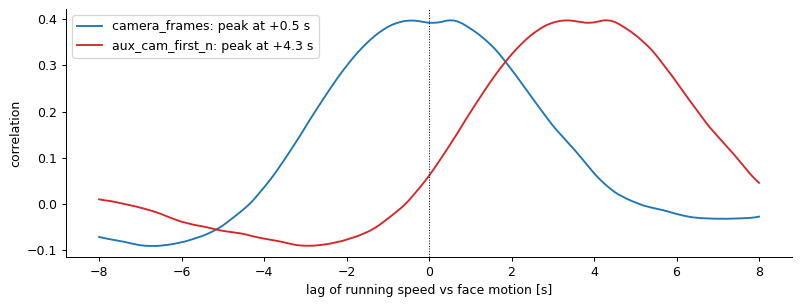

In [17]:
key = (fm.FacemapTask.Video & k_seg).fetch1("session_id", "scan_id")
key = dict(zip(("session_id", "scan_id"), key))
tt, raw = (be.TreadmillRecording.Channel & key & {"channel_name": "wheel_pos"}).fetch1("time", "data")
tt, raw = np.asarray(tt, float), np.asarray(raw, float)
ang = np.unwrap(np.radians((raw - raw.min()) / (raw.max() - raw.min()) * 360))
dt = 0.1
grid = np.arange(max(tt[0], 10), min(tt[-1], t_cam[-1]) - 10, dt)
speed = np.abs(np.gradient(np.interp(grid, tt, ang), dt))
def binned(t, x):
    i = np.digitize(t, grid) - 1; ok = (i >= 0) & (i < grid.size) & np.isfinite(t)
    return np.bincount(i[ok], weights=x[ok], minlength=grid.size) / np.maximum(np.bincount(i[ok], minlength=grid.size), 1)
z = lambda v: (v - v.mean()) / v.std()
lags = np.arange(-80, 81)
fig, ax = plt.subplots(figsize=(9, 3.5))
for m, c in (("camera_frames", "C0"), ("aux_cam_first_n", "C3")):
    e = z(np.log1p(binned(T[m], energy.astype(float)))); v = z(speed)
    cc = [np.mean(e[max(0, -L):e.size - max(0, L)] * v[max(0, L):v.size - max(0, -L)]) for L in lags]
    ax.plot(lags * dt, cc, c, label=f"{m}: peak at {lags[int(np.argmax(cc))] * dt:+.1f} s")
ax.axvline(0, color="k", lw=0.8, ls=":"); ax.set(xlabel="lag of running speed vs face motion [s]", ylabel="correlation")
ax.legend(); plt.tight_layout()

## 10. Comparing sessions within one run

All scans of a site run share one basis, so their positions in it can be compared. `FacialSignal.Position` holds the
median over frames of every component (all 500, not just the stored 100); `SegmentDistance` the Euclidean distances
between those medians (Leon's `svd_distances`). Distances across runs are meaningless: the bases differ.

mean distance between sessions 1983 vs within-session random-half reference 25


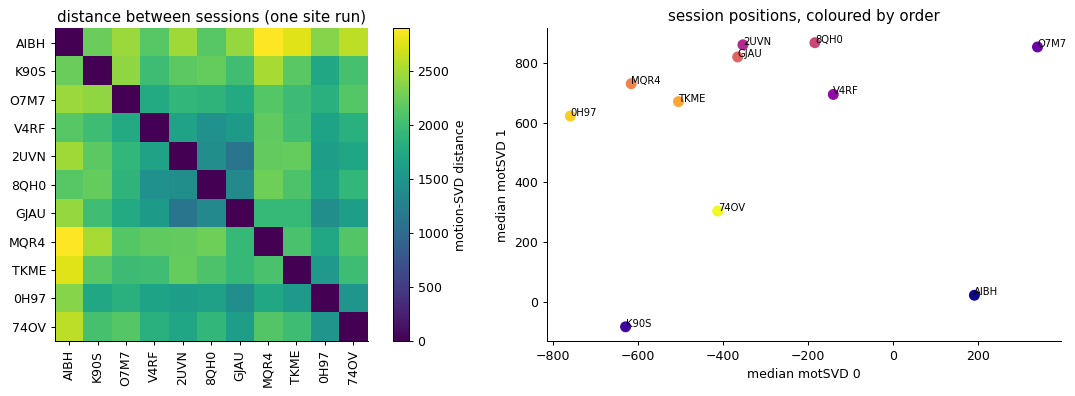

In [18]:
pos = pd.DataFrame((fm.FacialSignal.Position * fm.FacemapTask.Video & {"facemap_task_id": SITE_TASK}).fetch(
    "segment_index", "scan_id", "mot_median", "mov_median", "mot_within_random", "motion_median", as_dict=True)).sort_values("segment_index")
D = np.zeros((len(pos), len(pos)))
for a, b, d in zip(*(fm.SegmentDistance.Pair & {"facemap_task_id": SITE_TASK, "roi_no": 0}).fetch("segment_a", "segment_b", "mot_distance")):
    D[a, b] = D[b, a] = d
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
im = ax[0].imshow(D, cmap="viridis"); plt.colorbar(im, ax=ax[0], label="motion-SVD distance")
ax[0].set(xticks=range(len(pos)), yticks=range(len(pos)), title="distance between sessions (one site run)")
ax[0].set_xticklabels(pos.scan_id.str[-4:], rotation=90); ax[0].set_yticklabels(pos.scan_id.str[-4:])
M = np.vstack(pos.mot_median)
ax[1].scatter(M[:, 0], M[:, 1], c=pos.segment_index, cmap="plasma", s=60)
for x, y, lab in zip(M[:, 0], M[:, 1], pos.scan_id.str[-4:]): ax[1].annotate(lab, (x, y), fontsize=8)
ax[1].set(xlabel="median motSVD 0", ylabel="median motSVD 1", title="session positions, coloured by order")
plt.tight_layout()
print("mean distance between sessions %.0f vs within-session random-half reference %.0f" % (
    D[np.triu_indices(len(pos), 1)].mean(), pos.mot_within_random.mean()))

## 11. Validation against Leon's numbers

`roselab_leondrift.SessionFacemap` holds Leon's per-scan summaries for 168 scans (computed from his split files). The
ingest recomputes them from the site runs.

In [19]:
site_pos = pd.DataFrame((fm.FacialSignal.Position * fm.FacemapTask.Video * (fm.FacemapTask & {"facemap_paramset": "leon_site_concat_2026"})).fetch(
    "scan_id", "mot_median", "mov_median", "mot_within_temporal", "motion_median", as_dict=True))
L = pd.DataFrame(ld.SessionFacemap.fetch("scan_id", "mot_svd_median", "mov_svd_median", "mot_within_temporal", "motion_median", as_dict=True)).drop_duplicates("scan_id")
v = site_pos.merge(L, on="scan_id", suffixes=("", "_leon"))
v["mot_med_diff"] = [np.max(np.abs(np.asarray(a) - b)) for a, b in zip(v.mot_median, v.mot_svd_median)]
v["mov_med_diff"] = [np.max(np.abs(np.asarray(a) - b)) for a, b in zip(v.mov_median, v.mov_svd_median)]
print(f"{len(v)} of {len(L)} scans compared")
print("max |median difference|: motion %.2g, movie %.2g (float32 rounding)" % (v.mot_med_diff.max(), v.mov_med_diff.max()))
print("max |temporal reference difference| %.2g, max |motion median difference| %.2g" % (
    np.abs(v.mot_within_temporal - v.mot_within_temporal_leon).max(), np.abs(v.motion_median - v.motion_median_leon.astype(float)).max()))

168 of 168 scans compared
max |median difference|: motion 0.00012, movie 0.00098 (float32 rounding)
max |temporal reference difference| 0, max |motion median difference| 0


## 12. The 4-frame shift in 15 segments

Facemap rows should line up with video frames. Check: correlate facemap motion energy with the speed of the DLC face
markers **of the same video** at different lags. In 15 segments of three site runs the best lag is +4: Leon's
concatenated video lost 4 frames at one boundary, and the split by the original frame counts carried the shift into every
later segment (only the last one is 4 rows short). These segments carry `video_frame_offset = 4`, which `FrameSync`
applies.

subject
ROS-1912    [scan9FQBJFU7, scan9FQCR21N, scan9FQDWW8T, sca...
ROS-2147                         [scan9FVMJBHH, scan9FVRV8VM]
ROS-2356    [scan9G2ISHXX, scan9G2JZAI6, scan9G2L66VU, sca...


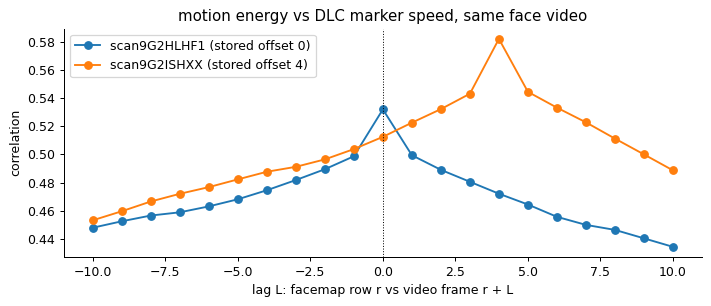

In [20]:
print(seg[seg.video_frame_offset != 0].groupby("subject").scan_id.apply(list).to_string())
def marker_speed(rk):
    pe = (md_.PoseEstimationNew & rk).fetch("KEY")
    q = lambda k: float(np.nanmedian(np.concatenate([np.asarray(x, float) for x in (md_.PoseEstimationNew.BodyPartPosition & k).fetch("likelihood")])))
    pe = max(pe, key=q)                                    # the best-tracked face model
    sp = []
    for x, y, l in zip(*(md_.PoseEstimationNew.BodyPartPosition & pe).fetch("x_pos", "y_pos", "likelihood")):
        x, y, l = (np.asarray(a, float) for a in (x, y, l))
        d = np.r_[np.nan, np.hypot(np.diff(x), np.diff(y))]; d[(l < 0.9) | np.r_[True, l[:-1] < 0.9]] = np.nan; sp.append(d)
    return np.nanmedian(np.vstack(sp), 0)
def lag_profile(task, scan):
    k = (fm.FacemapTask.Video & {"facemap_task_id": task, "scan_id": scan}).fetch1("KEY")
    rk = dict(zip(("session_id", "scan_id", "recording_id"), (fm.FacemapTask.Video & k).fetch1("session_id", "scan_id", "recording_id")))
    e = np.log1p((fm.FacialSignal.Trace & k & {"roi_no": 0}).fetch1("motion_energy").astype(float)); sp = np.log1p(marker_speed(rk))
    out = []
    for Lg in range(-10, 11):
        r = np.arange(e.size); vv = r + Lg; ok = (vv >= 0) & (vv < sp.size); a, b = e[r[ok]], sp[vv[ok]]; g = np.isfinite(a) & np.isfinite(b)
        out.append(np.corrcoef(a[g], b[g])[0, 1])
    return np.arange(-10, 11), np.array(out)
ros2356 = seg[(seg.subject == "ROS-2356") & (seg.video_assembly == "site_concat_registered")]
task_2356 = ros2356[ros2356.video_frame_offset == 4].facemap_task_id.iloc[0]
fig, ax = plt.subplots(figsize=(8, 3.5))
for scan_ in ("scan9G2HLHF1", "scan9G2ISHXX"):
    lg, c = lag_profile(task_2356, scan_)
    ax.plot(lg, c, marker="o", label=f"{scan_} (stored offset {int(seg[(seg.facemap_task_id == task_2356) & (seg.scan_id == scan_)].video_frame_offset.iloc[0])})")
ax.set(xlabel="lag L: facemap row r vs video frame r + L", ylabel="correlation", title="motion energy vs DLC marker speed, same face video")
ax.axvline(0, color="k", lw=0.8, ls=":"); ax.legend(); plt.tight_layout()

## 13. Special cases and caveats

In [21]:
print("runs without a movie SVD:", (fm.FacialSignal.Trace & "mov_svd IS NULL").fetch("facemap_task_id"))
print("segments where facemap rows != video frames:")
print(seg[~seg.frames_match.astype(bool)][["scan_id", "video_assembly", "n_frames", "n_frames_video", "video_frame_offset"]].to_string(index=False))

runs without a movie SVD: ['3e46821e5792']
segments where facemap rows != video frames:
     scan_id         video_assembly  n_frames  n_frames_video  video_frame_offset
scan9FVRV8VM site_concat_registered    294420          294424                   4
scan9G2OQSVH site_concat_registered    342240          342244                   4
scan9FQIOMIX site_concat_registered    294282          294286                   4


* **No stored camera events** (`camera_frames` = `no_events`): recordings that failed the audit's timing QC, and the
  newer cohort. Choose the method with `choose_sync_method` (section 8b): start-anchored for the 16 recordings with an
  unusual unsaved count, gate rule otherwise.
* **Start-anchored recordings** run past the last trigger in some cases (e.g. the last 20 and 22 frames of the two
  ROS-1881 scans); those rows have no time.
* **scan9FVK3VDN** has no body-camera paw model, so its start-anchored timing is inferred from the rule, not tested.
* **Shifted segments**: in segments shifted mid-run, the last 4 rows belong to the next video and have no time.
* **Positions of shifted segments** come from Leon's split and include 4 rows of the neighbouring video, as his own
  numbers do; a negligible effect on medians.
* **The eye is masked** in Leon's runs: facemap components do not carry pupil or gaze.
* **Only Leon's existing runs are stored** (`task_mode = 'load'`). Running facemap from the pipeline (`'trigger'`) is not
  implemented yet.

## 14. Query cheat-sheet

In [22]:
example = r"""
fm = dj.create_virtual_module("fm", "roselab_facemap")
scan = {"scan_id": "scan9FOWAIBH"}

# every run that contains this scan, and its generation
runs = (fm.FacemapTask * fm.FacemapParamSet) & (fm.FacemapTask.Video & scan)

# the site-run segment of this scan (shared basis across the site's sessions)
seg_key = (fm.FacemapProcessing.Segment * fm.FacemapTask.Video
           & scan & (fm.FacemapTask & {"facemap_paramset": "leon_site_concat_2026"})).fetch1("KEY")

# traces (facemap rows) and their DAQ times, with the method chosen per recording (section 8b)
energy, mot = (fm.FacialSignal.Trace & seg_key & {"roi_no": 0}).fetch1("motion_energy", "mot_svd")
from adamacs.schemas import facemap            # after facemap.activate("roselab_facemap"); or replicate choose_sync_method
t, method = facemap.frame_times(seg_key)       # NaN = row without a time

# position of each session in its run's basis, and distances between sessions
pos = fm.FacialSignal.Position & {"facemap_task_id": seg_key["facemap_task_id"]}
dist = fm.SegmentDistance.Pair & {"facemap_task_id": seg_key["facemap_task_id"]}
"""
print(example)


fm = dj.create_virtual_module("fm", "roselab_facemap")
scan = {"scan_id": "scan9FOWAIBH"}

# every run that contains this scan, and its generation
runs = (fm.FacemapTask * fm.FacemapParamSet) & (fm.FacemapTask.Video & scan)

# the site-run segment of this scan (shared basis across the site's sessions)
seg_key = (fm.FacemapProcessing.Segment * fm.FacemapTask.Video
           & scan & (fm.FacemapTask & {"facemap_paramset": "leon_site_concat_2026"})).fetch1("KEY")

# traces (facemap rows) and their DAQ times, with the method chosen per recording (section 8b)
energy, mot = (fm.FacialSignal.Trace & seg_key & {"roi_no": 0}).fetch1("motion_energy", "mot_svd")
from adamacs.schemas import facemap            # after facemap.activate("roselab_facemap"); or replicate choose_sync_method
t, method = facemap.frame_times(seg_key)       # NaN = row without a time

# position of each session in its run's basis, and distances between sessions
pos = fm.FacialSignal.Position & {"facemap_task_id": seg_key[